<a href="https://colab.research.google.com/github/catafiorini/Trabajo-Practico-ALC--2C-2026/blob/main/grupo_alfajorverde_TP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Trabajo Práctico - Álgebra Lineal Computacional
# - Calibración y Pose de la cámara -

## GRUPO: ALFAJOR VERDE

# Integrantes
* Chicolino deLuca Juan Pablo
* D'Angelo Genaro
* Fiorini Catalina
* Flores Garcia Emanuel

In [1]:
# Solo para Colab: traemos el repo con alc.py y los datos
import os
repo = '/content/Trabajo-Practico-ALC--2C-2026'
if os.path.exists(repo):
    !git -C {repo} pull
else:
    !git clone https://github.com/catafiorini/Trabajo-Practico-ALC--2C-2026.git

Already up to date.


In [10]:
import sys
sys.path.insert(0, '/content/Trabajo-Practico-ALC--2C-2026')

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import alc
from alc import *
np.set_printoptions(precision=4, suppress=True) #para printear las matrices mas esteticas

### Ejercicio 1 - DLT ecuaciones formales
a) Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

**Rango de Q**

Buscamos un m ≠ 0 tal que Q·m = 0, es decir, m ∈ Nu(Q). Como Q tiene 12 columnas, por el teorema de la dimensión:

    dim Nu(Q) = 12 − rg(Q)

Para que la solución sea única a menos de un factor de escala, todas las soluciones tienen que ser múltiplos de una sola, o sea, el núcleo tiene que ser una recta: dim Nu(Q) = 1. Entonces:

    rg(Q) = 11

* Si rg(Q) = 12, el núcleo es {0} y solo existe la solución trivial m = 0.
* Si rg(Q) < 11, el núcleo tiene dimensión mayor a 1, hay infinitas direcciones posibles y M no queda determinada.

**Cantidad mínima de puntos**

M tiene 12 coeficientes, pero como está definida a menos de un factor de escala tiene 11 grados de libertad. Cada correspondencia (U, V, W) ↔ (u, v) aporta 2 ecuaciones, es decir, 2 filas de Q. Para alcanzar rango 11 necesitamos:

    2n ≥ 11  →  n ≥ 5,5  →  n ≥ 6

Se necesitan **como mínimo 6 puntos**.

**Condición que deben cumplir**

Los puntos tienen que estar en posición general:

* **No pueden ser todos coplanares.** Si todos están en un mismo plano, Q pierde rango y la solución deja de ser única. Por eso el caso de puntos coplanares se resuelve con una homografía (Ejercicio 3).
* Tampoco pueden estar todos alineados.

En la mira de `calib/3d` hay 12 puntos repartidos en distintos planos, así que se cumple la condición.

b )Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 8.

**Planteo**

Queremos resolver:

    min  mᵀ QᵀQ m    sujeto a  ‖m‖ = 1

La restricción ‖m‖ = 1 evita la solución trivial m = 0 y fija la escala de M.

**Multiplicadores de Lagrange**

Como ‖m‖ = 1 es lo mismo que mᵀm = 1, armamos el lagrangiano:

    L(m, λ) = mᵀ QᵀQ m − λ (mᵀm − 1)

Derivando respecto de m e igualando a cero (QᵀQ es simétrica):

    2 QᵀQ m − 2 λ m = 0   →   QᵀQ m = λ m

Es decir, los candidatos a solución son los **autovectores de QᵀQ**.

**Cuál de los autovectores**

Si m es un autovector unitario con autovalor λ, el valor de la función es:

    mᵀ QᵀQ m = λ mᵀm = λ

Entonces, para minimizar, nos quedamos con el autovalor más chico. Como QᵀQ es simétrica y semidefinida positiva, todos sus autovalores son reales y mayores o iguales a 0.

**Conclusión:** el vector m que minimiza es el **autovector unitario de QᵀQ asociado a su menor autovalor**. Es equivalente al vector singular a derecha de Q asociado al menor valor singular. Con datos exactos ese autovalor es 0 y m está en el núcleo de Q.

**Cómo lo calculamos**

En `resolverDLT3D` usamos el método de la potencia inversa: el menor autovalor de QᵀQ es el mayor autovalor de (QᵀQ)⁻¹, así que iterar

    x_(k+1) = (QᵀQ)⁻¹ x_k / ‖(QᵀQ)⁻¹ x_k‖

converge a m. Para no calcular la inversa, factorizamos QᵀQ = LU una sola vez y, en cada paso, resolvemos dos sistemas triangulares (L z = x_k y U y = z). Por último, reacomodamos m como las 3 filas de M.

### Ejercicio 2 - Calibración con puntos 3D
:a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para

b) $\alpha_u = \alpha_v$

c) $K_{12}=0$

In [11]:
# ---- Ejercicio 2 a): calibración con la mira 3D

# Carpeta con los datos del template dentro del repo
CARPETA_DATOS = '/content/Trabajo-Practico-ALC--2C-2026/template-alumnos-20261020'
carpeta_3d = os.path.join(CARPETA_DATOS, 'calib', '3d')

# Coordenadas reales (U, V, W) de los 12 puntos de la mira
puntos_mundo = np.loadtxt(os.path.join(carpeta_3d, 'p_W_corners.txt'), delimiter=',')

# Posiciones en la imagen: cada fila es un cuadro del video con (u1, v1, ..., u12, v12)
esquinas_detectadas = np.loadtxt(os.path.join(carpeta_3d, 'detected_corners.txt'))

# Tomamos el primer cuadro (img_0001) y separamos u (columnas pares) y v (columnas impares)
u = esquinas_detectadas[0, 0::2]
v = esquinas_detectadas[0, 1::2]
puntos_imagen = np.vstack([u, v]).T     # matriz de 12 x 2

# Armamos Q y resolvemos el DLT para obtener M
Q = alc.obtenerQ3d(puntos_imagen, puntos_mundo)
M = alc.resolverDLT3D(Q)

# Descomponemos M en K, R y t
R, t, K = alc.devolverMatricesCalibracion3d(M)

print('K =\n', K)
print('\nR =\n', R)
print('\nt =', t)

K =
 [[425.8599  -0.0156 354.4185]
 [  0.     424.5653 256.8534]
 [  0.       0.       1.    ]]

R =
 [[ 0.6182  0.1292 -0.7753]
 [-0.3551  0.9259 -0.1288]
 [ 0.7012  0.3549  0.6183]]

t = [-18.1679 -14.5033  40.5913]


**Resultados del inciso a)**

* **K:** las distancias focales en píxeles son αu ≈ 425,86 y αv ≈ 424,57. Como son casi iguales, los píxeles son prácticamente cuadrados. El punto principal (u₀, v₀) ≈ (354,4; 256,9) queda cerca del centro de la imagen. El sesgo K12 ≈ −0,016 es despreciable frente a αu, lo que confirma que se puede suponer K12 = 0.
* **R:** es la rotación entre el sistema de la mira y el de la cámara.
* **t:** su tercera componente t₃ ≈ 40,6 es positiva, o sea que la mira queda delante de la cámara.

In [12]:
# ---- Ejercicio 2 b) y c): calibración con restricciones sobre K
# Usamos la misma M del inciso a) y solo cambiamos la descomposición

# b) Imponemos alfa_u = alfa_v
R_b, t_b, K_b = alc.devolverMatricesCalibracion3d(M, alfasIguales=True)

print('b) alfa_u = alfa_v')
print('K =\n', K_b)
print('R =\n', R_b)
print('t =', t_b)

# c) Imponemos K12 = 0 (sin sesgo)
R_c, t_c, K_c = alc.devolverMatricesCalibracion3d(M, sinSesgo=True)

print('\nc) K12 = 0')
print('K =\n', K_c)
print('R =\n', R_c)
print('t =', t_c)

b) alfa_u = alfa_v
K =
 [[425.2126  -0.0156 354.4185]
 [  0.     425.2126 256.8534]
 [  0.       0.       1.    ]]
R =
 [[ 0.6182  0.1292 -0.7753]
 [-0.3551  0.9259 -0.1288]
 [ 0.7012  0.3549  0.6183]]
t = [-18.1956 -14.4812  40.5913]

c) K12 = 0
K =
 [[425.8599   0.     354.4185]
 [  0.     424.5653 256.8534]
 [  0.       0.       1.    ]]
R =
 [[ 0.6182  0.1292 -0.7753]
 [-0.3551  0.9259 -0.1288]
 [ 0.7012  0.3549  0.6183]]
t = [-18.1674 -14.5033  40.5913]


**Resultados de los incisos b) y c)**

* **b) αu = αv:** ambas distancias focales quedan en el promedio, ≈ 425,21 px. Como en el inciso a) ya diferían menos de un 0,5 %, el cambio es muy chico.
* **c) K12 = 0:** el resto de K queda igual que en a). El sesgo original (≈ −0,016) era despreciable, así que imponerlo en 0 casi no cambia nada.
* **R** es prácticamente la misma en los tres casos (coincide en los 4 decimales mostrados), porque las modificaciones sobre K son muy chicas.
* **t** cambia apenas en sus dos primeras componentes, y t₃ ≈ 40,59 se mantiene. La traslación se recalcula con la K nueva, y K afecta sobre todo a las coordenadas u y v.

En conclusión, las hipótesis habituales de píxeles cuadrados (αu = αv) y sin sesgo (K12 = 0) son razonables para esta cámara.

### Ejercicio 3 - Calibración con puntos coplanares
Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.

a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

**Rango de Q**

Con el mismo razonamiento que en el Ejercicio 1: h tiene 9 componentes, pero como H está definida a menos de un factor de escala, tiene 8 grados de libertad. Para que la solución sea única a menos de escala, el núcleo de Q tiene que ser una recta:

    dim Nu(Q) = 9 − rg(Q) = 1   →   rg(Q) = 8

Cada punto aporta 2 ecuaciones, así que se necesitan **al menos 4 puntos**, sin que haya 3 alineados. El tablero tiene 11 × 7 = 77 esquinas internas, mucho más que el mínimo.

**Sistema de coordenadas del tablero**

Tomamos el origen en una esquina interna, los ejes U y V a lo largo de los lados y W = 0. Así, las esquinas internas tienen coordenadas (30·i, 30·j) mm, con i = 0, …, 10 y j = 0, …, 6.

In [13]:
# ---- Ejercicio 3: coordenadas del tablero (en mm)
# Esquinas internas: 11 x 7, cuadrados de 30 mm, W = 0
# Recorremos fila por fila: primero las 11 esquinas con j = 0, después j = 1, etc.

tam_cuadrado = 30.0
puntos_tablero = np.zeros((77, 2))

k = 0
for j in range(7):          # filas del tablero (eje V)
    for i in range(11):     # columnas del tablero (eje U)
        puntos_tablero[k, 0] = tam_cuadrado * i     # U
        puntos_tablero[k, 1] = tam_cuadrado * j     # V
        k = k + 1

print(puntos_tablero.shape)
print(puntos_tablero[:13])

(77, 2)
[[  0.   0.]
 [ 30.   0.]
 [ 60.   0.]
 [ 90.   0.]
 [120.   0.]
 [150.   0.]
 [180.   0.]
 [210.   0.]
 [240.   0.]
 [270.   0.]
 [300.   0.]
 [  0.  30.]
 [ 30.  30.]]


**Detección de las esquinas del tablero**

En la carpeta `calib/coplanar` solo están las imágenes, sin las posiciones (u, v) de las esquinas. Para obtenerlas usamos `cv2.findChessboardCorners`, únicamente para detectar las esquinas en la imagen. La calibración (homografías, K y poses) está implementada con nuestras funciones del módulo `alc`.

In [14]:
# ---- Ejercicio 3: detección de las esquinas en cada imagen
carpeta_coplanar = os.path.join(CARPETA_DATOS, 'calib', 'coplanar')
archivos = os.listdir(carpeta_coplanar)

vistas = []             # número de cada imagen que se pudo usar
puntos_imagen_2d = []   # esquinas (u, v) detectadas en cada imagen, 77 x 2

for numero in range(1, 21):
    nombre = 'Im_R_' + str(numero) + '.png'

    # Si la imagen no está en la carpeta, la salteamos
    if nombre not in archivos:
        continue

    # Leemos la imagen en escala de grises y buscamos las 11 x 7 esquinas internas
    imagen = cv2.imread(os.path.join(carpeta_coplanar, nombre), cv2.IMREAD_GRAYSCALE)
    encontrado, esquinas = cv2.findChessboardCorners(imagen, (11, 7))

    if encontrado:
        vistas.append(numero)
        puntos_imagen_2d.append(esquinas.reshape(77, 2))
    else:
        print(nombre, ': no se detectó el tablero')

print('Imágenes usadas:', vistas)

Imágenes usadas: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


In [15]:
# ---- Ejercicio 3: homografía de cada vista
lista_H = []

for k in range(len(vistas)):
    # Armamos Q con las esquinas de la imagen y las coordenadas del tablero
    Q_2d = alc.obtenerQ2d(puntos_imagen_2d[k], puntos_tablero)

    # Resolvemos Q h = 0 y reacomodamos h como la matriz H de 3 x 3
    H = alc.resolverDLT2D(Q_2d)
    lista_H.append(H)

print('Cantidad de homografías:', len(lista_H))
print('Tamaño de Q:', Q_2d.shape)
print('H de la primera imagen =\n', lista_H[0])

Cantidad de homografías: 10
Tamaño de Q: (154, 9)
H de la primera imagen =
 [[ 0.0036 -0.0001  0.963 ]
 [ 0.0001  0.0035  0.2695]
 [ 0.     -0.      0.0026]]


In [16]:
# ---- Ejercicio 3 a): matriz K
# Cada homografía aporta 2 filas a A (perpendicularidad e igual norma de r1 y r2)
A_zhang = alc.armarA(lista_H)
print('Tamaño de A:', A_zhang.shape)

# Resolvemos A b = 0, armamos B y obtenemos K por Cholesky
K_2d = alc.calcularMatrizK2D(A_zhang)
print('\nK =\n', K_2d)

Tamaño de A: (20, 6)

K =
 [[742.7054  -0.6847 520.4613]
 [  0.     753.9445 299.3382]
 [  0.       0.       1.    ]]


**Resultado del inciso a)**

* Las distancias focales en píxeles son αu ≈ 742,7 y αv ≈ 753,9. Difieren un 1,5 %, así que los píxeles son casi cuadrados.
* El sesgo K12 ≈ −0,68 es despreciable frente a αu.
* El punto principal (u₀, v₀) ≈ (520,5; 299,3) está cerca del centro de la imagen, que mide 1024 × 576 y tiene su centro en (512, 288).

### Ejercicio 4 - Fútbol
a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo.
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$.
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.

In [17]:
import numpy as np
import pandas as pd

datos = pd.read_csv(CARPETA_DATOS + '/salguero/world_img_pts.csv', sep=';')   # ajustá la ruta según dónde lo tengas
print(datos.shape)
print(datos.columns.tolist())
datos.head()

(5, 12)
['pts', 'X', 'Y', 'Z', 'u_0', 'v_0', 'u_1', 'v_1', 'u_2', 'v_2', 'u_3', 'v_3']


,pts,X,Y,Z,u_0,v_0,u_1,v_1,u_2,v_2,u_3,v_3
0,6,-4.0,3,0.0,281,474,255,490,469,581,446,563
1,36,4.0,0,0.0,889,521,1071,577,1147,653,1118,621
2,40,6.5,3,0.1,1139,493,1403,550,1425,625,1396,590
3,41,-5.0,14,0.1,418,385,437,377,627,485,600,466
4,42,-5.0,76,0.1,833,262,997,227,1094,357,1064,331


In [18]:
# Separar puntos del mundo y de la imagen por vista
# Puntos en el plano del piso (U, V) = (X, Y), iguales para todas las vistas
objPts = datos[['X', 'Y']].to_numpy(dtype=np.float64)   # forma (5, 2)

# Puntos en la imagen para cada vista k
n_vistas = 4
imgPts_vistas = []
for k in range(n_vistas):
    imgPts_k = datos[['u_' + str(k), 'v_' + str(k)]].to_numpy(dtype=np.float64)  # forma (5, 2)
    imgPts_vistas.append(imgPts_k)

print(objPts)
print(imgPts_vistas[0])

[[-4.   3. ]
 [ 4.   0. ]
 [ 6.5  3. ]
 [-5.  14. ]
 [-5.  76. ]]
[[ 281.  474.]
 [ 889.  521.]
 [1139.  493.]
 [ 418.  385.]
 [ 833.  262.]]


In [19]:
# Estimar las homografías y K
Hlst = []
for k in range(n_vistas):
    Q_k = obtenerQ2d(imgPts_vistas[k], objPts)
    H_k = resolverDLT2D(Q_k)
    H_k = H_k / H_k[2, 2]     # normalizamos para que H[2,2] = 1
    Hlst.append(H_k)

A = armarA(Hlst)
K_salguero = calcularMatrizK2D(A)
print(K_salguero)

[[2803.1419 1278.3942  334.842 ]
 [   0.      230.9822  213.2788]
 [   0.        0.        1.    ]]


In [20]:
# Centro de la imagen (1600 x 1200)
cx, cy = 800, 600
T = np.array([[1, 0, -cx],
              [0, 1, -cy],
              [0, 0, 1]], dtype=np.float64)

# Homografías con el origen de píxeles en el centro de la imagen
Hlst_centradas = []
for H_k in Hlst:
    Hlst_centradas.append(alc.multiplicar(T, H_k))

A_c = alc.armarA(Hlst_centradas)

# Sistema reducido: incógnitas (B11, B33)
A_red = np.zeros((A_c.shape[0], 2))
A_red[:, 0] = A_c[:, 0] + A_c[:, 2]
A_red[:, 1] = A_c[:, 5]
A_red = A_red / np.max(np.abs(A_red))   # escalado, igual que en calcularMatrizK2D

x = alc.resolverHomogeneo(A_red)
f = np.sqrt(x[1] / x[0])

K_simple = np.array([[f, 0, cx],
                     [0, f, cy],
                     [0, 0, 1]])
print(K_simple)

[[3482.4881    0.      800.    ]
 [   0.     3482.4881  600.    ]
 [   0.        0.        1.    ]]


In [22]:
# Cargar los 51 puntos de la vista inicial
gs = np.loadtxt(os.path.join(CARPETA_DATOS + '/salguero/gs_10_09_point_correspondences_v5.txt'))

objPts_gs = gs[1:3, :].T     # (X, Y) de cada punto -> forma (51, 2)
mundo_gs  = gs[1:4, :].T     # (X, Y, Z) -> forma (51, 3), para reproyectar
imgPts_gs = gs[4:6, :].T     # (u, v) -> forma (51, 2)

In [23]:
# Homografía y pose
H_gs = alc.resolverDLT2D(alc.obtenerQ2d(imgPts_gs, objPts_gs))
H_gs = H_gs / H_gs[2, 2]

R_gs, t_gs = alc.obtenerPose2D(H_gs, K_simple)

Error RMS: 195.58550849092592 px
Error máximo: 564.3717190424081 px


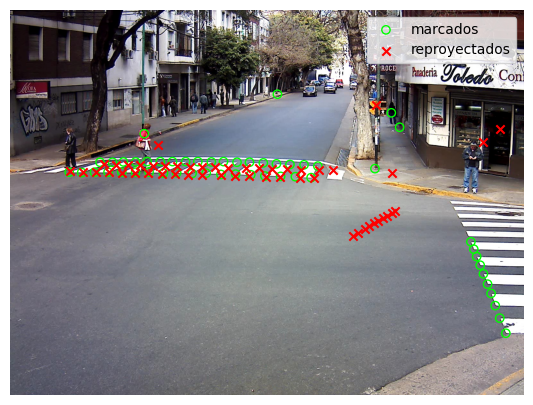

In [26]:
def reproyectar(K, R, t, puntos_mundo):
    # puntos de la cámara: R X + t  (una columna por punto)
    X_cam = alc.multiplicar(R, puntos_mundo.T) + t.reshape(3, 1)
    q = alc.multiplicar(K, X_cam)
    # pasamos de homogéneas a píxeles dividiendo por la tercera coordenada
    return (q[0:2, :] / q[2, :]).T

reproy_gs = reproyectar(K_simple, R_gs, t_gs, mundo_gs)
errores = np.sqrt(np.sum((reproy_gs - imgPts_gs) ** 2, axis=1))
print('Error RMS:', np.sqrt(np.mean(errores ** 2)), 'px')
print('Error máximo:', np.max(errores), 'px')

img_inicial = plt.imread(os.path.join(CARPETA_DATOS +'/salguero/img_10_18_47_351.jpg'))
plt.figure(figsize=(8, 5))
plt.imshow(img_inicial)
plt.scatter(imgPts_gs[:, 0], imgPts_gs[:, 1], marker='o', facecolors='none', edgecolors='lime', label='marcados')
plt.scatter(reproy_gs[:, 0], reproy_gs[:, 1], marker='x', color='red', label='reproyectados')
plt.legend()
plt.axis('off')
plt.show()

In [27]:
A_gs = alc.armarA([alc.multiplicar(T, H_gs)])

A_gs_red = np.zeros((A_gs.shape[0], 2))
A_gs_red[:, 0] = A_gs[:, 0] + A_gs[:, 2]
A_gs_red[:, 1] = A_gs[:, 5]
A_gs_red = A_gs_red / np.max(np.abs(A_gs_red))

x_gs = alc.resolverHomogeneo(A_gs_red)
f_gs = np.sqrt(x_gs[1] / x_gs[0])

K_gs = np.array([[f_gs, 0, cx],
                 [0, f_gs, cy],
                 [0, 0, 1]])
print(K_gs)

[[2001.1461    0.      800.    ]
 [   0.     2001.1461  600.    ]
 [   0.        0.        1.    ]]


Error RMS: 14.24485872592537 px
Error máximo: 36.30844711015479 px


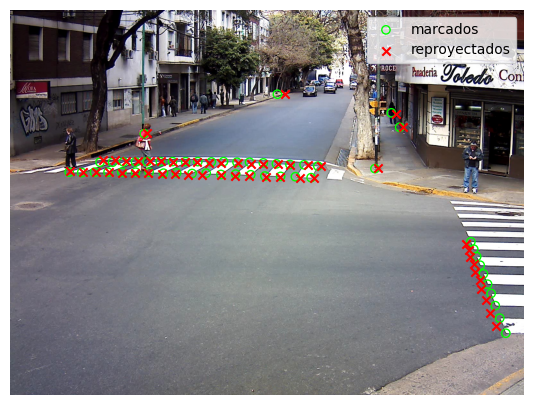

R =
 [[ 0.9874  0.1585  0.002 ]
 [ 0.0343 -0.2014 -0.9789]
 [-0.1547  0.9666 -0.2043]]
t = [-3.2982 -1.0238 23.0585]


In [28]:
R_gs2, t_gs2 = alc.obtenerPose2D(H_gs, K_gs)

reproy_gs2 = reproyectar(K_gs, R_gs2, t_gs2, mundo_gs)
errores2 = np.sqrt(np.sum((reproy_gs2 - imgPts_gs) ** 2, axis=1))
print('Error RMS:', np.sqrt(np.mean(errores2 ** 2)), 'px')
print('Error máximo:', np.max(errores2), 'px')

plt.figure(figsize=(8, 5))
plt.imshow(img_inicial)
plt.scatter(imgPts_gs[:, 0], imgPts_gs[:, 1], marker='o', facecolors='none', edgecolors='lime', label='marcados')
plt.scatter(reproy_gs2[:, 0], reproy_gs2[:, 1], marker='x', color='red', label='reproyectados')
plt.legend()
plt.axis('off')
plt.show()

print('R =\n', R_gs2)
print('t =', t_gs2)

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad
a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

### Ejercicio 6 - Aterrizaje suave
a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$.

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)